# First look at the raw YouTube trending data

Before cleaning anything, check what the three country files actually contain: size, date coverage, duplicates, missing values, and columns that may not be usable. Nothing is changed or saved here; the findings at the end decide what the cleaning step has to do.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAW_YOUTUBE_DIR = Path("../data/raw/youtube")
COUNTRIES = ["IN", "US", "GB"]

In [2]:
raw_trending = pd.concat(
    [
        pd.read_csv(RAW_YOUTUBE_DIR / f"{country}_youtube_trending_data.csv").assign(country=country)
        for country in COUNTRIES
    ],
    ignore_index=True,
)
raw_trending["trending_date"] = pd.to_datetime(raw_trending["trending_date"])
raw_trending.shape

(788855, 17)

In [3]:
raw_trending[["video_id", "title", "publishedAt", "channelTitle", "categoryId",
              "trending_date", "view_count", "likes", "comment_count", "country"]].head()

,video_id,title,publishedAt,channelTitle,categoryId,trending_date,view_count,likes,comment_count,country
0,Iot0eF6EoNA,Sadak 2 | Official Trailer | Sanjay | Pooja | ...,2020-08-12T04:31:41Z,FoxStarHindi,24,2020-08-12 00:00:00+00:00,9885899,224925,350210,IN
1,x-KbnJ9fvJc,Kya Baat Aa : Karan Aujla (Official Video) Tan...,2020-08-11T09:00:11Z,Rehaan Records,10,2020-08-12 00:00:00+00:00,11308046,655450,405146,IN
2,KX06ksuS6Xo,Diljit Dosanjh: CLASH (Official) Music Video |...,2020-08-11T07:30:02Z,Diljit Dosanjh,10,2020-08-12 00:00:00+00:00,9140911,296533,30058,IN
3,UsMRgnTcchY,Dil Ko Maine Di Kasam Video | Amaal M Ft.Ariji...,2020-08-10T05:30:49Z,T-Series,10,2020-08-12 00:00:00+00:00,23564512,743931,136942,IN
4,WNSEXJJhKTU,"Baarish (Official Video) Payal Dev,Stebin Ben ...",2020-08-11T05:30:13Z,VYRLOriginals,10,2020-08-12 00:00:00+00:00,6783649,268817,22984,IN


## Size and date coverage

Each row is one video on one day's trending list, so a video that trends for 6 days appears 6 times.

In [4]:
raw_trending.groupby("country").agg(
    rows=("video_id", "size"),
    unique_videos=("video_id", "nunique"),
    unique_channels=("channelId", "nunique"),
    first_trending_date=("trending_date", "min"),
    last_trending_date=("trending_date", "max"),
)

,rows,unique_videos,unique_channels,first_trending_date,last_trending_date
country,,,,,
GB,268791,47607,7571,2020-08-12 00:00:00+00:00,2024-04-15 00:00:00+00:00
IN,251277,78847,4521,2020-08-12 00:00:00+00:00,2024-04-15 00:00:00+00:00
US,268787,47142,8302,2020-08-12 00:00:00+00:00,2024-04-15 00:00:00+00:00


In [5]:
def find_missing_days(country_rows):
    trending_dates = country_rows["trending_date"]
    calendar = pd.date_range(trending_dates.min(), trending_dates.max(), freq="D")
    return calendar.difference(trending_dates.unique())


missing_days_by_country = {
    country: find_missing_days(raw_trending[raw_trending["country"] == country])
    for country in COUNTRIES
}
for country, missing_days in missing_days_by_country.items():
    print(f"{country}: {len(missing_days)} calendar days with no trending list")

IN: 20 calendar days with no trending list
US: 20 calendar days with no trending list
GB: 20 calendar days with no trending list


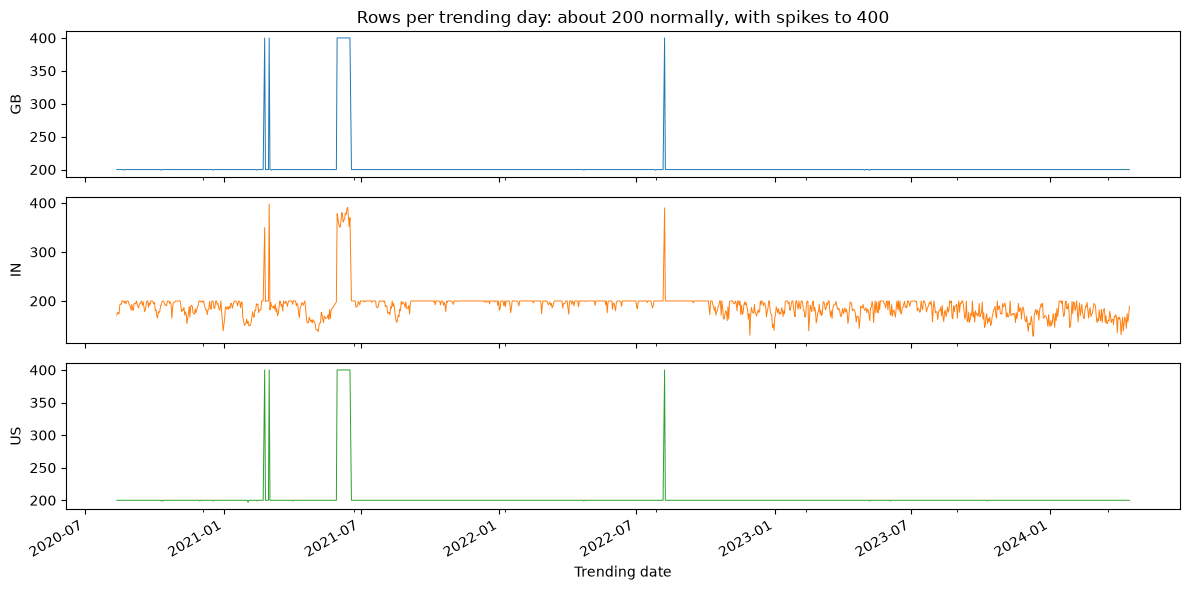

In [6]:
rows_per_day = raw_trending.groupby(["trending_date", "country"]).size().unstack("country")

axes = rows_per_day.plot(subplots=True, figsize=(12, 6), linewidth=0.7, sharex=True, legend=False)
for ax, country in zip(axes, rows_per_day.columns):
    ax.set_ylabel(country)
axes[0].set_title("Rows per trending day: about 200 normally, with spikes to 400")
axes[-1].set_xlabel("Trending date")
plt.tight_layout()
plt.show()

## Duplicates

Two kinds: rows that are identical in every column, and the same video listed twice on the same day.

In [7]:
same_day_key = ["country", "video_id", "trending_date"]

pd.DataFrame({
    "full_row_duplicates": raw_trending.duplicated().groupby(raw_trending["country"]).sum(),
    "same_video_same_day": raw_trending.duplicated(same_day_key).groupby(raw_trending["country"]).sum(),
})

,full_row_duplicates,same_video_same_day
country,,
GB,124,3793
IN,75,3166
US,83,4070


In [8]:
same_day_rows = raw_trending[raw_trending.duplicated(same_day_key, keep=False)]
view_counts_differ = same_day_rows.groupby(same_day_key)["view_count"].nunique().gt(1)
print(f"{view_counts_differ.mean():.1%} of same-day repeats have different view counts")

example_key = view_counts_differ[view_counts_differ].index[0]
same_day_rows.set_index(same_day_key).sort_index().loc[example_key, ["title", "view_count", "likes", "comment_count"]]

94.8% of same-day repeats have different view counts


title  \
country video_id    trending_date                                                   
GB      --14w5SOEUs 2021-06-12 00:00:00+00:00  Migos - Avalanche (Official Video)   
                    2021-06-12 00:00:00+00:00  Migos - Avalanche (Official Video)   

                                               view_count   likes  \
country video_id    trending_date                                   
GB      --14w5SOEUs 2021-06-12 00:00:00+00:00     3317372  202153   
                    2021-06-12 00:00:00+00:00     3963014  218568   

                                               comment_count  
country video_id    trending_date                             
GB      --14w5SOEUs 2021-06-12 00:00:00+00:00          14721  
                    2021-06-12 00:00:00+00:00          15442

The chart above shows the repeats bunch into a few periods. One guess: when a day was missed, the next day's run collected two lists. Check whether days with repeats come right after a missing day.

In [9]:
for country in COUNTRIES:
    country_rows = raw_trending[raw_trending["country"] == country]
    days_with_repeats = pd.DatetimeIndex(
        country_rows.loc[country_rows.duplicated(["video_id", "trending_date"]), "trending_date"].unique()
    )
    missing_days = missing_days_by_country[country]
    right_after_gap = days_with_repeats.isin(missing_days.shift(1, freq="D"))
    print(f"{country}: {len(days_with_repeats)} days contain repeats, "
          f"{right_after_gap.sum()} of them are the day right after a missing day")

IN: 25 days contain repeats, 2 of them are the day right after a missing day


US: 23 days contain repeats, 2 of them are the day right after a missing day
GB: 28 days contain repeats, 2 of them are the day right after a missing day


## Missing and placeholder values

In [10]:
raw_trending.isna().sum().loc[lambda null_counts: null_counts > 0]

channelTitle        1
description     28386
dtype: int64

In [11]:
pd.DataFrame({
    "tags_placeholder_none": raw_trending["tags"].eq("[None]").groupby(raw_trending["country"]).sum(),
    "title_mojibake": raw_trending["title"].str.contains("â€|Ã", regex=True).groupby(raw_trending["country"]).sum(),
})

,tags_placeholder_none,title_mojibake
country,,
GB,44335,5
IN,43717,8
US,44494,0


## Dislikes

YouTube stopped returning public dislike counts in December 2021. If that shows up here, the column cannot be used for any analysis that spans the full period.

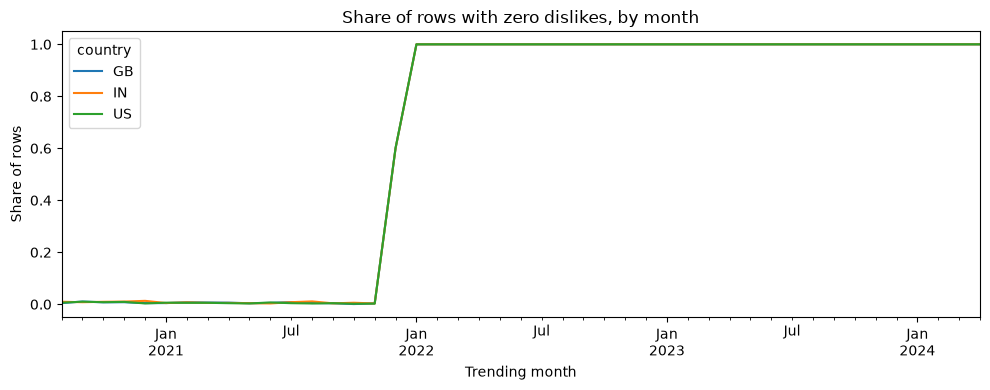

country
GB   2021-12-13 00:00:00+00:00
IN   2021-12-13 00:00:00+00:00
US   2021-12-13 00:00:00+00:00
Name: last_date_with_dislikes, dtype: datetime64[ns, UTC]

In [12]:
monthly_zero_dislike_share = (
    raw_trending.groupby(["country", pd.Grouper(key="trending_date", freq="MS")])["dislikes"]
    .apply(lambda dislikes: dislikes.eq(0).mean())
    .unstack("country")
)

ax = monthly_zero_dislike_share.plot(figsize=(10, 4))
ax.set(title="Share of rows with zero dislikes, by month", xlabel="Trending month", ylabel="Share of rows")
plt.tight_layout()
plt.show()

raw_trending[raw_trending["dislikes"] > 0].groupby("country")["trending_date"].max().rename("last_date_with_dislikes")

## Disabled comments and ratings

Zero likes or zero comments could mean nobody engaged, or that the feature was turned off. These need to be told apart before computing engagement ratios.

In [13]:
raw_trending.groupby("country").agg(
    ratings_disabled=("ratings_disabled", "sum"),
    zero_likes=("likes", lambda likes: likes.eq(0).sum()),
    comments_disabled=("comments_disabled", "sum"),
    zero_comments=("comment_count", lambda comments: comments.eq(0).sum()),
    zero_views=("view_count", lambda views: views.eq(0).sum()),
)

,ratings_disabled,zero_likes,comments_disabled,zero_comments,zero_views
country,,,,,
GB,1504,1505,4838,5862,94
IN,2290,2297,1697,2251,16
US,1538,1538,3509,4575,80


In [14]:
pd.crosstab(raw_trending["ratings_disabled"], raw_trending["likes"].eq(0).rename("zero_likes"))

zero_likes,False,True
ratings_disabled,,
False,783515,8
True,0,5332


## View counts

View counts are heavily skewed, so the median is more useful than the mean for describing a typical trending video.

In [15]:
raw_trending.groupby("country")["view_count"].describe(percentiles=[0.5, 0.99]).round(0)

,count,mean,std,min,50%,99%,max
country,,,,,,,
GB,268791.0,2190558.0,6651493.0,0.0,774505.0,27125888.0,1.406330e+09
IN,251277.0,2793858.0,6979626.0,0.0,947434.0,32288050.0,2.644074e+08
US,268787.0,2734467.0,9794087.0,0.0,936871.0,32389728.0,1.407644e+09


## Categories

`categoryId` is a number. Each country has a JSON file that maps it to a name; check that every id in the data has one.

In [16]:
def load_category_names(country):
    with open(RAW_YOUTUBE_DIR / f"{country}_category_id.json", encoding="utf-8") as category_file:
        category_items = json.load(category_file)["items"]
    return {int(item["id"]): item["snippet"]["title"] for item in category_items}


for country in COUNTRIES:
    category_names = load_category_names(country)
    ids_in_data = raw_trending.loc[raw_trending["country"] == country, "categoryId"].unique()
    unmapped_ids = sorted(set(ids_in_data) - set(category_names))
    print(f"{country}: {len(ids_in_data)} category ids in data, unmapped: {unmapped_ids}")

IN: 15 category ids in data, unmapped: [np.int64(29)]
US: 15 category ids in data, unmapped: []
GB: 15 category ids in data, unmapped: [np.int64(29)]


## What the cleaning step has to handle

- **Same-day repeats.** 11,029 rows (IN 3,166, US 4,070, GB 3,793) are a video listed twice on the same day. In 94.8% of them the view counts differ, so they are two snapshots taken on the same day, not copies. They bunch into Feb-Mar 2021, late May-June 2021 and Aug 2022, when the list seems to have been collected twice a day. Keep the snapshot with the highest view count, since views only go up, so that is the later one. This also removes the 282 exact duplicate rows.
- **Missing days.** Each country has 20 calendar days with no list. The guess that repeats are a catch-up for those days was wrong: only 2 of the 23-28 days with repeats come right after a gap. Gaps will slightly undercount trending duration for videos that span them.
- **Dislikes.** Zero for every row after 2021-12-13 in all three countries. Drop the column.
- **Ratings disabled.** 5,332 rows, and likes are 0 in every one of them. These likes are missing, not zero, so they must be excluded from like ratios rather than counted as 0. The same applies to the 10,044 rows with comments disabled.
- **Zero comments without the flag.** Zero comments exceed comments disabled by 554 (IN) to 1,066 (US) rows. These may be genuine zeros; keep them, but flag the uncertainty.
- **Tags.** 132,546 rows have the string `[None]`, which means no tags. Convert to empty.
- **Descriptions.** 28,386 are missing. Descriptions are not used in the analysis, so leave them.
- **Category 29** (Nonprofits & Activism) is missing from the IN and GB category files but present in the US file. Build one mapping from all three files.
- **Encoding.** The check flagged 13 rows (3 videos), but on inspection the characters are genuine, for example SÃO PAULO in a Portuguese title. No encoding fix needed.
- **Zero views.** 190 rows from 26 videos show 0 views, mostly Google Doodles, The Royal Family and YouTube's own announcements. These videos hide their view counter, so 0 means unknown. Treat as missing.
- **View counts** are heavily skewed: the median is 0.77M (GB) to 0.95M (IN), the maximum is 1.4B. Use medians and log scales.

Not a cleaning issue, but worth testing later: India has the fewest rows but the most unique videos (78,847 vs about 47,000), and its daily list is often shorter than 200. India's trending list seems to turn over faster.